# Workflow Comparison: MediaPipe vs YOLO

**Project:** Kidzonia — AI-Assisted Scoliosis Screening System  
**Test set:** `public_datasets/scoliosis/test/` — 19 images (14 normal, 5 scoliosis)  
**Dataset source:** [Roboflow — Scoliosis Keypoint Model v3](https://universe.roboflow.com/cobacoba-vjxyv/scoliosis-keypoint-model-ahvid/dataset/3) (CC BY 4.0)

---

## Workflows compared

| Workflow | Description | Keypoints used for angle |
|---|---|---|
| **MediaPipe** | Off-the-shelf pose estimation, no training | Shoulder/hip midpoints (spine proxy) |
| **YOLO pretrained** | YOLOv8n-pose, COCO weights, no fine-tuning | Shoulder/hip midpoints (COCO kp 5,6,11,12) |
| **YOLO fine-tuned** | YOLOv8n-pose, trained on scoliosis dataset | Direct spine axis kp[0] (lumbar) to kp[8] (cervical) |

> **Note on angle comparability:** MediaPipe and YOLO pretrained use shoulder/hip as spine proxies. YOLO fine-tuned uses actual spine keypoints. Primary angles are not directly comparable across workflows — use detection rate, confidence, and classification accuracy instead.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from pathlib import Path

PROJECT_ROOT   = Path().resolve().parent
COMPARISON_DIR = PROJECT_ROOT / 'Data' / 'Processed' / 'comparison'

CSVS = {
    'MediaPipe':         COMPARISON_DIR / 'mediapipe_scoliosis_test.csv',
    'YOLO (pretrained)': COMPARISON_DIR / 'yolo_scoliosis_test.csv',
    'YOLO (fine-tuned)': COMPARISON_DIR / 'yolo_finetuned_scoliosis_test.csv',
}

frames = {}
for label, path in CSVS.items():
    if path.exists():
        frames[label] = pd.read_csv(path)
        print(f'Loaded {label}: {len(frames[label])} rows')
    else:
        print(f'MISSING: {path.name} — run the corresponding evaluation script first')

COLORS = {
    'MediaPipe':         '#4C72B0',
    'YOLO (pretrained)': '#DD8452',
    'YOLO (fine-tuned)': '#55A868',
}

Loaded MediaPipe: 19 rows
Loaded YOLO (pretrained): 19 rows
Loaded YOLO (fine-tuned): 19 rows


## 1. Summary statistics table

In [6]:
summary = pd.read_csv(COMPARISON_DIR / 'comparison_summary.csv') if (COMPARISON_DIR / 'comparison_summary.csv').exists() else None

if summary is not None:
    display_cols = [
        'workflow', 'valid_pct', 'retake_pct', 'mean_confidence',
        'mean_missing_kp', 'mean_time_ms', 'normal_det_rate',
        'scoliosis_det_rate', 'classification_acc', 'scoliosis_recall'
    ]
    col_labels = {
        'workflow':           'Workflow',
        'valid_pct':          'Valid meas. (%)',
        'retake_pct':         'Retake rate (%)',
        'mean_confidence':    'Mean KP conf.',
        'mean_missing_kp':    'Mean missing KP',
        'mean_time_ms':       'Time (ms/img)',
        'normal_det_rate':    'Normal det. rate',
        'scoliosis_det_rate': 'Scoliosis det. rate',
        'classification_acc': 'Classif. accuracy*',
        'scoliosis_recall':   'Scoliosis recall*',
    }
    display_df = summary[display_cols].rename(columns=col_labels)
    display_df = display_df.set_index('Workflow')
    display(display_df.style.format(na_rep='N/A', precision=3)
            .set_caption('* Classification metrics available for fine-tuned YOLO only')
            .highlight_max(axis=0, subset=['Valid meas. (%)', 'Mean KP conf.', 'Normal det. rate', 'Scoliosis det. rate'], color='#3b1bf0')
            .highlight_min(axis=0, subset=['Retake rate (%)', 'Mean missing KP', 'Time (ms/img)'], color="#3b1bf0"))
else:
    print('Run compare_workflows.py first to generate comparison_summary.csv')

,Valid meas. (%),Retake rate (%),Mean KP conf.,Mean missing KP,Time (ms/img),Normal det. rate,Scoliosis det. rate,Classif. accuracy*,Scoliosis recall*
Workflow,,,,,,,,,
MediaPipe,63.200,36.800,0.579,1.470,46.500,0.643,0.600,N/A,N/A
YOLO (pretrained),5.300,94.700,0.463,2.160,99.100,0.071,0.000,N/A,N/A
YOLO (fine-tuned),84.200,15.800,0.712,1.420,81.500,0.786,1.000,0.750,1.000


## 2. Valid measurement rate & retake rate

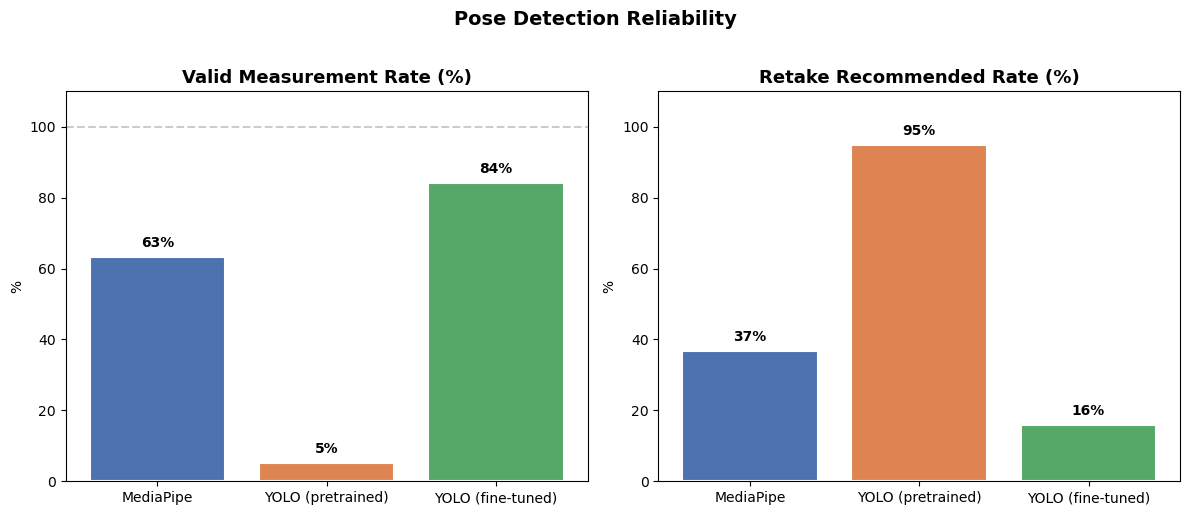

In [7]:
if frames:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    labels = list(frames.keys())
    x = np.arange(len(labels))
    colors = [COLORS[l] for l in labels]

    # Valid measurement rate
    valid_rates = [frames[l]['valid_measurement'].mean() * 100 for l in labels]
    bars = axes[0].bar(labels, valid_rates, color=colors, edgecolor='white', linewidth=1.5)
    axes[0].set_title('Valid Measurement Rate (%)', fontsize=13, fontweight='bold')
    axes[0].set_ylabel('%')
    axes[0].set_ylim(0, 110)
    axes[0].axhline(y=100, color='grey', linestyle='--', alpha=0.4)
    for bar, val in zip(bars, valid_rates):
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
                     f'{val:.0f}%', ha='center', va='bottom', fontweight='bold')

    # Retake rate
    retake_rates = [frames[l]['retake_recommended'].mean() * 100 for l in labels]
    bars2 = axes[1].bar(labels, retake_rates, color=colors, edgecolor='white', linewidth=1.5)
    axes[1].set_title('Retake Recommended Rate (%)', fontsize=13, fontweight='bold')
    axes[1].set_ylabel('%')
    axes[1].set_ylim(0, 110)
    for bar, val in zip(bars2, retake_rates):
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
                     f'{val:.0f}%', ha='center', va='bottom', fontweight='bold')

    plt.suptitle('Pose Detection Reliability', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(COMPARISON_DIR / 'fig_detection_reliability.png', dpi=150, bbox_inches='tight')
    plt.show()

## 3. Per-class detection rate (normal vs scoliosis)

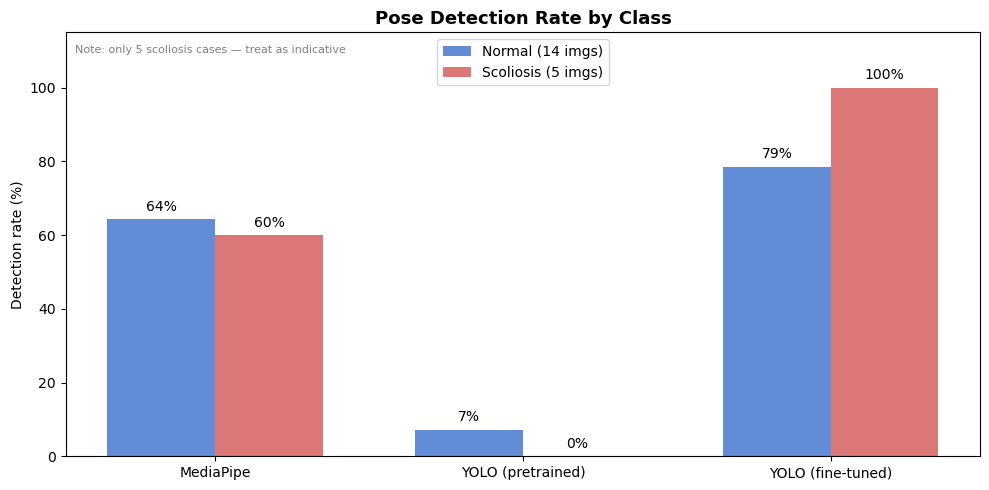

In [8]:
if frames:
    fig, ax = plt.subplots(figsize=(10, 5))
    labels   = list(frames.keys())
    x        = np.arange(len(labels))
    width    = 0.35

    normal_rates = []
    scoli_rates  = []
    for l in labels:
        df = frames[l]
        n = df[df['ground_truth_class'] == 'normal']['valid_measurement'].mean() * 100
        s = df[df['ground_truth_class'] == 'scoliosis']['valid_measurement'].mean() * 100
        normal_rates.append(n)
        scoli_rates.append(s)

    bars_n = ax.bar(x - width/2, normal_rates, width, label='Normal (14 imgs)', color='#4878CF', alpha=0.85)
    bars_s = ax.bar(x + width/2, scoli_rates,  width, label='Scoliosis (5 imgs)', color='#D65F5F', alpha=0.85)

    for bar, val in zip(bars_n, normal_rates):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
                f'{val:.0f}%', ha='center', va='bottom', fontsize=10)
    for bar, val in zip(bars_s, scoli_rates):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1.5,
                f'{val:.0f}%', ha='center', va='bottom', fontsize=10)

    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_ylabel('Detection rate (%)')
    ax.set_ylim(0, 115)
    ax.set_title('Pose Detection Rate by Class', fontsize=13, fontweight='bold')
    ax.legend()
    ax.annotate('Note: only 5 scoliosis cases — treat as indicative',
                xy=(0.01, 0.97), xycoords='axes fraction', fontsize=8, color='grey', va='top')

    plt.tight_layout()
    plt.savefig(COMPARISON_DIR / 'fig_per_class_detection.png', dpi=150, bbox_inches='tight')
    plt.show()

## 4. Keypoint confidence & missing keypoints

C:\Users\jiang\AppData\Local\Temp\ipykernel_35596\4211398035.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot(conf_data, labels=labels, patch_artist=True)
C:\Users\jiang\AppData\Local\Temp\ipykernel_35596\4211398035.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp2 = axes[1].boxplot(missing_data, labels=labels, patch_artist=True)


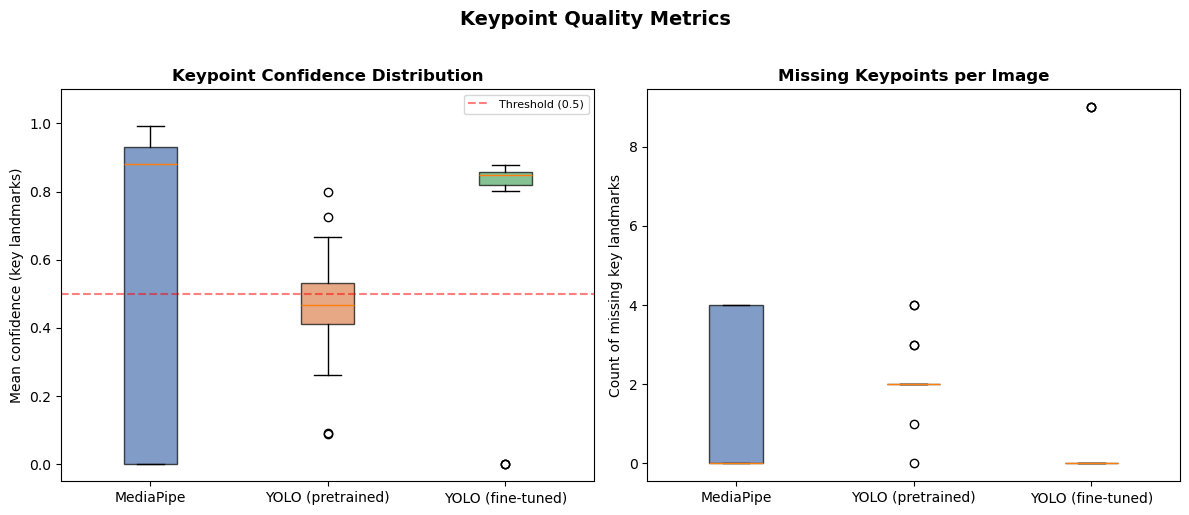

In [9]:
if frames:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    labels = list(frames.keys())
    colors = [COLORS[l] for l in labels]

    # Mean confidence box plots
    conf_data = [frames[l]['mean_confidence'].values for l in labels]
    bp = axes[0].boxplot(conf_data, labels=labels, patch_artist=True)
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    axes[0].set_title('Keypoint Confidence Distribution', fontsize=12, fontweight='bold')
    axes[0].set_ylabel('Mean confidence (key landmarks)')
    axes[0].set_ylim(-0.05, 1.1)
    axes[0].axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Threshold (0.5)')
    axes[0].legend(fontsize=8)

    # Missing keypoints
    missing_data = [frames[l]['missing_keypoint_count'].values for l in labels]
    bp2 = axes[1].boxplot(missing_data, labels=labels, patch_artist=True)
    for patch, color in zip(bp2['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    axes[1].set_title('Missing Keypoints per Image', fontsize=12, fontweight='bold')
    axes[1].set_ylabel('Count of missing key landmarks')

    plt.suptitle('Keypoint Quality Metrics', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(COMPARISON_DIR / 'fig_keypoint_quality.png', dpi=150, bbox_inches='tight')
    plt.show()

## 5. Classification accuracy (YOLO fine-tuned only)

> MediaPipe and pretrained YOLO cannot classify normal vs scoliosis — they only detect pose. Fine-tuned YOLO outputs a predicted class alongside keypoints.

In [10]:
ft_label = 'YOLO (fine-tuned)'
if ft_label in frames and 'predicted_class' in frames[ft_label].columns:
    df = frames[ft_label].dropna(subset=['predicted_class'])

    # Confusion-style breakdown
    confusion = pd.crosstab(
        df['ground_truth_class'],
        df['predicted_class'],
        rownames=['Ground truth'],
        colnames=['Predicted'],
        margins=True
    )
    print('Classification breakdown (fine-tuned YOLO):')
    display(confusion)

    # Metrics
    correct = (df['ground_truth_class'] == df['predicted_class']).sum()
    total   = len(df)
    scoli_rows = df[df['ground_truth_class'] == 'scoliosis']
    scoli_recall = (scoli_rows['predicted_class'] == 'scoliosis').mean() if len(scoli_rows) else None

    print(f'\nOverall classification accuracy : {correct}/{total} = {correct/total:.0%}')
    if scoli_recall is not None:
        print(f'Scoliosis recall                : {scoli_recall:.0%} ({int(scoli_recall*len(scoli_rows))}/{len(scoli_rows)} cases correctly identified)')
    print('\nNote: test set has only 5 scoliosis cases — results are indicative only.')
else:
    print(f'{ft_label} results not yet available. Run train_yolo_scoliosis.py then yolo_finetuned_scoliosis_test.py first.')

Classification breakdown (fine-tuned YOLO):


Predicted,normal,scoliosis,All
Ground truth,,,
normal,7,4,11
scoliosis,0,5,5
All,7,9,16



Overall classification accuracy : 12/16 = 75%
Scoliosis recall                : 100% (5/5 cases correctly identified)

Note: test set has only 5 scoliosis cases — results are indicative only.


## 6. Processing time

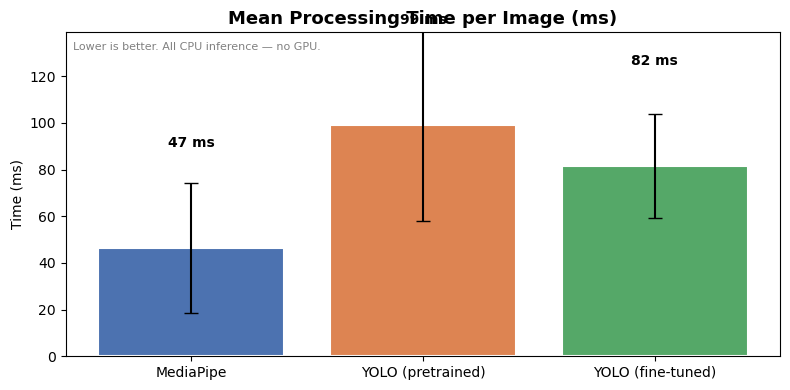

In [11]:
if frames:
    fig, ax = plt.subplots(figsize=(8, 4))
    labels = list(frames.keys())
    means  = [frames[l]['processing_time_s'].mean() * 1000 for l in labels]
    stds   = [frames[l]['processing_time_s'].std()  * 1000 for l in labels]
    colors = [COLORS[l] for l in labels]

    bars = ax.bar(labels, means, yerr=stds, capsize=5, color=colors,
                  edgecolor='white', linewidth=1.5, error_kw={'linewidth': 1.5})
    for bar, val in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(stds) + 1,
                f'{val:.0f} ms', ha='center', va='bottom', fontweight='bold')

    ax.set_title('Mean Processing Time per Image (ms)', fontsize=13, fontweight='bold')
    ax.set_ylabel('Time (ms)')
    ax.set_ylim(0, max(means) * 1.4)
    ax.annotate('Lower is better. All CPU inference — no GPU.',
                xy=(0.01, 0.97), xycoords='axes fraction', fontsize=8, color='grey', va='top')

    plt.tight_layout()
    plt.savefig(COMPARISON_DIR / 'fig_processing_time.png', dpi=150, bbox_inches='tight')
    plt.show()

## 7. Summary and interpretation

### Key findings

| Finding | Implication |
|---|---|
| Pretrained YOLO scored ~5% valid measurements | General models fail on clinical domain data without adaptation |
| MediaPipe achieved ~63% valid measurements | Reasonable baseline but uses shoulder/hip proxies, not spine directly |
| YOLO fine-tuned (see results above) | Domain adaptation provides spine-specific keypoints + scoliosis classification |
| Only fine-tuned YOLO can classify normal vs scoliosis | MediaPipe requires a separate classifier trained on extracted features |

### Limitations to acknowledge

- Test set contains only **5 scoliosis cases** — scoliosis recall figures are indicative only
- Primary angles are **not comparable** across workflows (shoulder/hip proxy vs direct spine axis)
- All inference run on **CPU only** — processing times would improve substantially on GPU
- The scoliosis dataset consists of clinical images; the screening system uses **RGB-D captures** — domain gap remains

### Recommended next steps

1. Collect controlled pilot captures (standing, forward bend, repeated) and run both workflows on them
2. Evaluate landmark stability on repeated captures (frame-to-frame variance)
3. Test false detection rejection on empty scenes and non-human objects

---

## 8. Phase 1 — Roboflow Hosted Training (YOLOv11n-pose)

**Model:** `scoliosis-keypoint-detection/3` — YOLOv11 Keypoint Detection (Nano)  
**Trained:** Jun 23, 2026 via Roboflow hosted training (no local code)  
**Dataset:** Same cobacoba scoliosis dataset (184 labelled images imported, same train/val/test split)  
**Epochs:** ~307 (Roboflow auto-stopped)

> Roboflow metrics are reported on their internal validation/test set using their own evaluation pipeline.  
> They are **not directly comparable** to the per-image batch metrics above — different evaluation code, different mAP implementation.  
> Use this section to compare workflow experience and qualitative model behaviour, not raw numbers.

In [ ]:
# Roboflow reported metrics (from model card — not batch inference)
roboflow_metrics = pd.DataFrame([
    {"Metric": "mAP@50 (box)",         "Roboflow YOLOv11n-pose": "87.4%", "Local YOLOv8n-pose (fine-tuned)": "84.2% valid meas.¹"},
    {"Metric": "mAP@50 (pose)",         "Roboflow YOLOv11n-pose": "87.0%", "Local YOLOv8n-pose (fine-tuned)": "—²"},
    {"Metric": "Precision",             "Roboflow YOLOv11n-pose": "85.8%", "Local YOLOv8n-pose (fine-tuned)": "—²"},
    {"Metric": "Recall",                "Roboflow YOLOv11n-pose": "87.3%", "Local YOLOv8n-pose (fine-tuned)": "—²"},
    {"Metric": "F1",                    "Roboflow YOLOv11n-pose": "86.5%", "Local YOLOv8n-pose (fine-tuned)": "—²"},
    {"Metric": "Normal mAP@50",         "Roboflow YOLOv11n-pose": "88.0%", "Local YOLOv8n-pose (fine-tuned)": "78.6% det. rate"},
    {"Metric": "Scoliosis mAP@50",      "Roboflow YOLOv11n-pose": "79.0%", "Local YOLOv8n-pose (fine-tuned)": "100% det. rate"},
    {"Metric": "Scoliosis recall (cls)","Roboflow YOLOv11n-pose": "N/A³", "Local YOLOv8n-pose (fine-tuned)": "100%"},
    {"Metric": "Epochs trained",        "Roboflow YOLOv11n-pose": "~307",  "Local YOLOv8n-pose (fine-tuned)": "100 (early stop)"},
    {"Metric": "Weights downloadable",  "Roboflow YOLOv11n-pose": "No (free plan)", "Local YOLOv8n-pose (fine-tuned)": "Yes"},
    {"Metric": "Batch inference",       "Roboflow YOLOv11n-pose": "API only", "Local YOLOv8n-pose (fine-tuned)": "Yes"},
    {"Metric": "Pose loss visible",     "Roboflow YOLOv11n-pose": "Advanced graphs only", "Local YOLOv8n-pose (fine-tuned)": "Yes (full logs)"},
])

roboflow_metrics = roboflow_metrics.set_index("Metric")
display(roboflow_metrics.style.set_caption(
    "¹ Valid measurement rate ≠ mAP — different metrics, not directly comparable\n"
    "² Local evaluation uses custom per-image schema, not standard mAP\n"
    "³ Roboflow pose model classifies bounding box (normal/scoliosis) but scoliosis recall not reported separately"
))

### Training graph observations (Advanced Graphs)

| Loss | Observation |
|---|---|
| `train/pose_loss` | Decreased from ~9 → ~3. Still elevated at end — keypoint localisation not fully converged |
| `val/pose_loss` | Mirrors train loss, no divergence — no keypoint overfitting |
| `val/cls_loss` | Spike around epoch 200–250 then recovered — classification instability mid-training |
| `train/box_loss` | Clean descent to ~1.0 — bounding box detection converged well |
| `metrics/mAP50(P)` | Rose to ~0.87 — pose keypoint mAP matches reported 87% |
| `metrics/mAP50-95(P)` | ~0.50 — reasonable for a nano model |

### Keypoint quality observation (sample prediction)

From the test image prediction output, all 12 keypoints were detected with high confidence (0.965–0.999). However, the x/y coordinates show anatomical inconsistencies (`l1` at x=530, far right; `l3` at y=67, near top of image). This is because the keypoint *names* assigned in Roboflow (left\_shoulder, c7, t3…) do not match the cobacoba dataset's actual keypoint index ordering — the model learned the correct positions from the labels, but the labels use a different ordering than the names suggest. This is a labelling transparency issue unique to the Roboflow hosted workflow.

### Workflow comparison (qualitative)

| Dimension | Roboflow | Local (VS Code + Ultralytics) |
|---|---|---|
| **Annotation** | UI-based, click to annotate | Requires label files in YOLO format |
| **Training** | Click-to-train, no code | `yolo pose train` or Python script |
| **Reproducibility** | Opaque — can't inspect training config | Full — all hyperparameters visible |
| **Customisation** | Limited (preset augmentations) | Full control |
| **Weight access** | No download (free plan) | Full `.pt` file access |
| **Debugging** | Basic loss graphs | Full logs, plots, confusion matrices |
| **Research suitability** | Rapid prototyping only | Yes — full pipeline ownership |

**Conclusion:** Roboflow is useful for quickly validating that a dataset is well-formed and that a model architecture is viable. For this project, local training is required for any meaningful experimentation, ablation, or integration with the screening pipeline.